# SmartSpray — Module 3 Disease Classification (70 / 15 / 15 rebuild)

This notebook **only reads** the artifacts written by `scripts/m3_train_classifier.py`. It does not train and it does not touch the test split again.

| Item | Value |
|---|---|
| Dataset | PlantVillage tomato subset (early blight, healthy, late blight, septoria) |
| Split | de-duplicated, stratified, `random_state=42`, 70 / 15 / 15 |
| Model | EfficientNetB0 (ImageNet) → GAP → Dropout 0.3 → Dense 256 → Dropout 0.2 → Dense 4 |
| Selection | validation split only |
| Test | evaluated once (lock file `models/classification/eval/TEST_EVALUATED.lock`) |

In [1]:
import json, hashlib
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
MODEL_DIR = ROOT / 'models' / 'classification'
EVAL = MODEL_DIR / 'eval'
manifest = json.loads((MODEL_DIR / 'split_manifest.json').read_text())
metrics = json.loads((EVAL / 'metrics.json').read_text())
history = json.loads((EVAL / 'training_history.json').read_text())
promotion = json.loads((EVAL / 'promotion_record.json').read_text())
print('Artifacts loaded from', EVAL)

Artifacts loaded from /home/claude/SmartSpray/models/classification/eval


## 1. Dataset audit and split

In [2]:
print('Raw image files :', manifest['raw_file_total'], manifest['raw_file_counts'])
print('Exact duplicates removed :', len(manifest['excluded']['exact_duplicates']))
print('Unique images   :', manifest['unique_images'])
print('Seed / method   :', manifest['random_seed'], '|', manifest['split_method'])
df = pd.DataFrame(manifest['split_counts']).T
df['total'] = df.sum(axis=1)
df.loc['all'] = df.sum()
display(df)

Raw image files : 5016 {'early_blight': 800, 'healthy': 1273, 'late_blight': 1526, 'septoria_leaf_spot': 1417}
Exact duplicates removed : 9
Unique images   : 5007
Seed / method   : 42 | sklearn.model_selection.train_test_split called twice, stratify=labels, random_state=RANDOM_SEED: (1) 70% train vs 30% holdout; (2) holdout 50/50 -> validation/test


,early_blight,healthy,late_blight,septoria_leaf_spot,total
train,560,888,1064,992,3504
validation,120,191,228,212,751
test,120,190,229,213,752
all,800,1269,1521,1417,5007


In [3]:
checks = manifest['leakage_checks']
display(pd.Series(checks, name='value').to_frame())
assert all(v == 0 for k, v in checks.items() if 'overlap' in k)
print('Zero overlap between train / validation / test (by path and by SHA-256).')

,value
path_overlap_train_validation,0
hash_overlap_train_validation,0
path_overlap_train_test,0
hash_overlap_train_test,0
path_overlap_validation_test,0
hash_overlap_validation_test,0
every_unique_image_in_exactly_one_split,True
dropped_duplicates_absent_from_splits,True


Zero overlap between train / validation / test (by path and by SHA-256).


In [4]:
pd.DataFrame(manifest['excluded']['exact_duplicates'])[['path', 'duplicate_of']]

,path,duplicate_of
0,healthy/cfd491d6-4af5-4728-8f0e-0d330a07174a__...,healthy/1af0bfe1-4bcf-4b8b-be66-5d0953eb647e__...
1,healthy/505465db-407b-4e0a-8110-7479dad5261c__...,healthy/37203047-d8ba-43f7-b31e-d496c41c569c__...
2,healthy/e786ac89-29fe-47e3-b49e-b9a9ee7edd9d__...,healthy/37aad83b-7ff8-4b35-b3ed-fb8e0f54910b__...
3,healthy/d2ce7896-6fa4-45e6-96c5-d162da0e3e1c__...,healthy/9662364c-aaba-45e3-b907-10792d60578c__...
4,late_blight/2c47b891-3c97-48f1-a2cc-5aa53d3a11...,late_blight/1a69b38b-c4eb-42c4-9584-bcb14fb8db...
5,late_blight/5de6da85-f8c4-48c4-b463-3e6bd78884...,late_blight/3fae9c64-18f0-4a67-9f97-554248bb1b...
6,late_blight/bd4f09bd-ee85-4ab1-bce0-8cde3fdd7f...,late_blight/48c55974-9fe9-4f4b-94f7-c8cd127d1e...
7,late_blight/e5d707cd-077c-43af-bda9-6138e516ff...,late_blight/5f21282c-e2ef-4c4a-ace1-b5701fe7ef...
8,late_blight/d82b634e-9a19-497b-b698-aaf100d622...,late_blight/861d8b00-57a4-46b0-b51a-09d102dbe1...


## 2. Training (validation-only model selection)

Phase 1 trains the head with the backbone frozen. Phase 2 fine-tunes the top 30 backbone layers. Phase 3 (pre-registered) fine-tunes blocks 5–7 and is accepted only if validation improves. BatchNorm stays frozen throughout.

Backbone weights: efficientnetb0_imagenet_notop.weights.h5


,value
image_size,224
batch_size,32
epochs_head_max,20
epochs_finetune_max,10
lr_head,0.001
lr_finetune,0.00001
fine_tune_layers,30
batchnorm_frozen_in_phase2,True
dropout,0.3
early_stop_patience,5


,phase,epochs,minutes,best val_acc,min val_loss
0,phase1,20,34.4,0.966711,0.114156
1,phase2,10,17.8,0.974700,0.097412
2,phase3,4,9.6,0.980027,0.060918


Selected checkpoint: {'phase': 'phase3', 'epoch': 1, 'val_accuracy': 0.9800266027450562, 'val_loss': 0.060918111354112625}


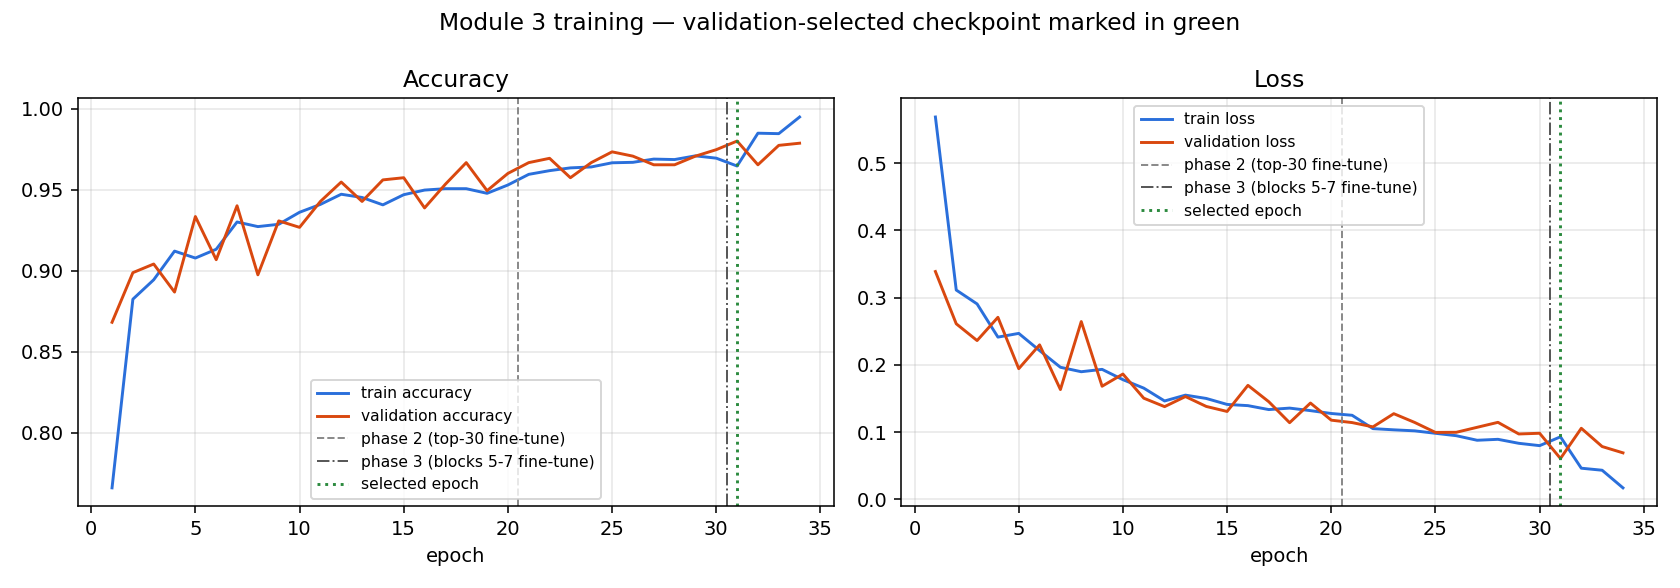

In [5]:
print('Backbone weights:', history['backbone_weights_source'].split('/')[-1])
display(pd.Series(history['hyperparameters']).to_frame('value'))
rows = []
for ph in ('phase1', 'phase2', 'phase3'):
    if ph in history:
        h = history[ph]['history']
        rows.append({'phase': ph, 'epochs': history[ph]['epochs_run'],
                     'minutes': round(history[ph]['minutes'], 1),
                     'best val_acc': max(h['val_accuracy']),
                     'min val_loss': min(h['val_loss'])})
display(pd.DataFrame(rows))
print('Selected checkpoint:', history['selected_checkpoint'])
display(Image(str(EVAL / 'training_curves.png')))

In [6]:
print('TTA decision (validation):', history['validation_inference_decision'])
print('Calibration (validation):', history['calibration'])

TTA decision (validation): {'acc_plain': 0.9800266311584553, 'acc_tta_hflip': 0.9813581890812251, 'nll_plain': 0.06091810017824173, 'nll_tta_hflip': 0.05742223560810089, 'use_tta': True}
Calibration (validation): {'method': 'temperature scaling fitted on validation NLL', 'temperature': 0.9010197026101795, 'val_nll_before': 0.05742223560810089, 'val_nll_after': 0.05684776231646538, 'val_ece_before': 0.009108510180891118, 'val_ece_after': 0.008241431095628651}


## 3. Independent test evaluation (single pass)

In [7]:
print((EVAL / 'test_evaluation_printout.txt').read_text())


Total images:            5007  (raw files 5016, 9 exact duplicates removed)
Training:                3504
Validation:              751
Test:                    752

Test Loss:               0.0546
Test Accuracy:           0.9734  (97.34%)

Classification Report:
                    precision    recall  f1-score   support

      early_blight     0.9244    0.9167    0.9205       120
           healthy     0.9896    1.0000    0.9948       190
       late_blight     0.9955    0.9607    0.9778       229
septoria_leaf_spot     0.9636    0.9953    0.9792       213

          accuracy                         0.9734       752
         macro avg     0.9683    0.9682    0.9681       752
      weighted avg     0.9736    0.9734    0.9733       752

Macro F1:                0.9681
Weighted F1:             0.9733

Confusion Matrix (rows = true, cols = predicted):
                        early_blight       healthy   late_blight  septoria_lea
early_blight                     110             1         

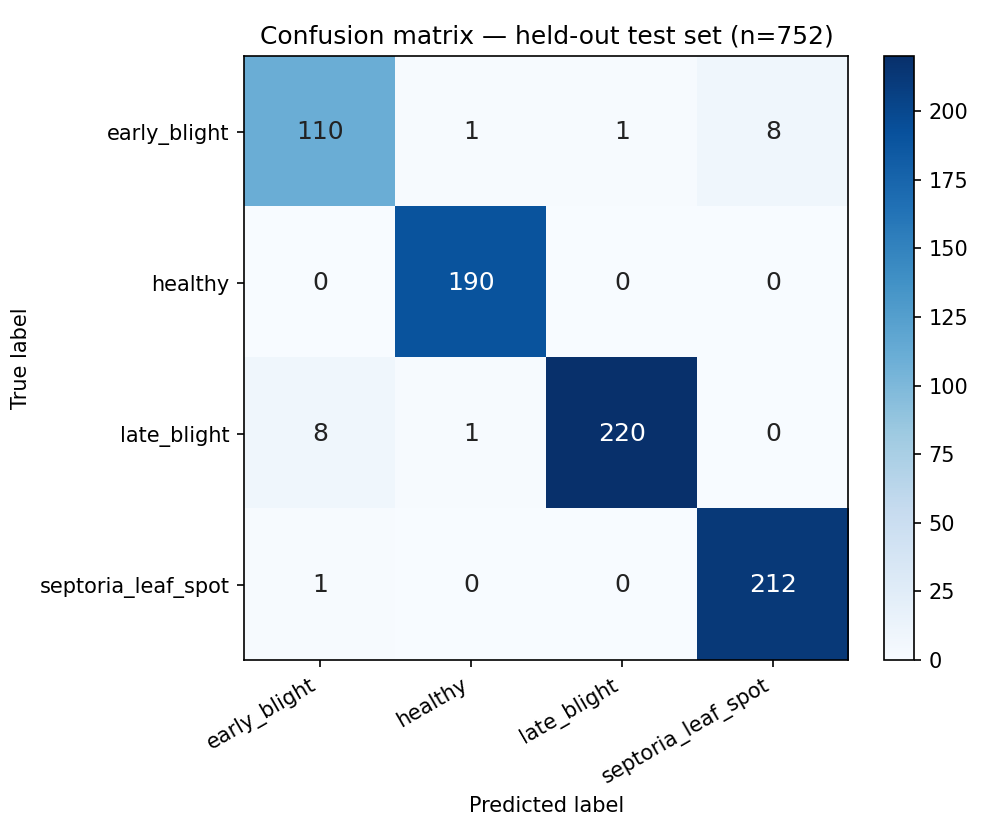

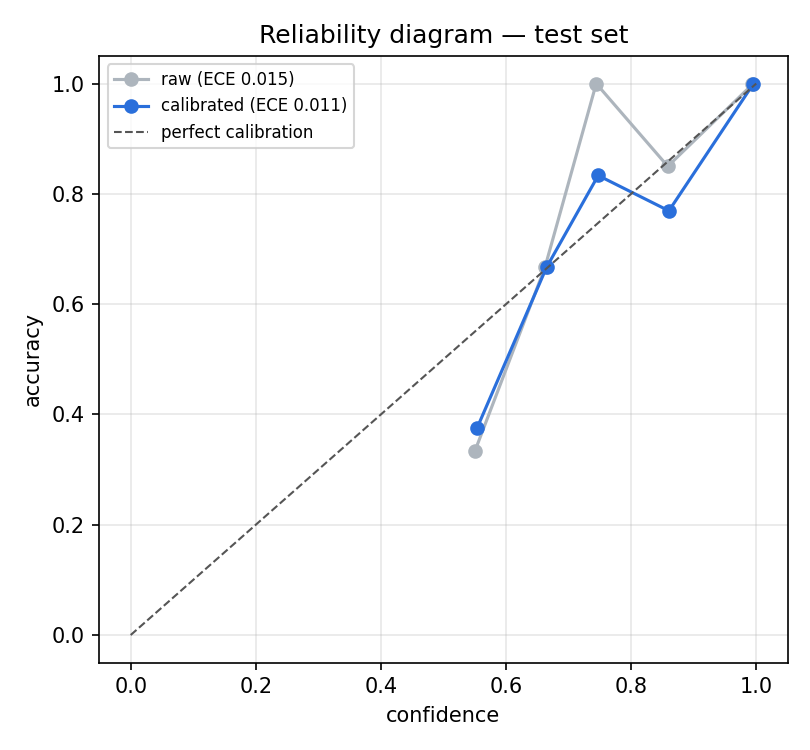

In [8]:
display(Image(str(EVAL / 'confusion_matrix.png')))
display(Image(str(EVAL / 'reliability_diagram.png')))

In [9]:
pd.read_csv(EVAL / 'misclassified.csv')

,path,true_label,pred_label,confidence
0,early_blight/240300f1-a601-4363-84e8-670af8a12...,early_blight,septoria_leaf_spot,0.4311
1,early_blight/43e84adf-0897-47dc-97a4-94ef0e83e...,early_blight,septoria_leaf_spot,0.7761
2,early_blight/52082b15-4350-415a-be8c-bb0e0fc3a...,early_blight,septoria_leaf_spot,0.9944
3,early_blight/73cf82cf-a099-4243-a7a6-b06c79eed...,early_blight,septoria_leaf_spot,0.7150
4,early_blight/784f629e-77a3-4d3b-b83c-9ef67b646...,early_blight,septoria_leaf_spot,0.6154
5,early_blight/7a259d3d-cca4-4041-88ec-d3140cd96...,early_blight,late_blight,0.6274
6,early_blight/90c69e4c-c526-4f72-b0b0-4127fc6ac...,early_blight,septoria_leaf_spot,0.8910
7,early_blight/9b617d8b-b252-4a29-9af5-10ea563eb...,early_blight,healthy,0.5532
8,early_blight/bde8917a-9b0c-4a7b-8ff1-26f31609d...,early_blight,septoria_leaf_spot,0.4995
9,early_blight/c9ff37ca-a310-49ad-8978-0913b3c55...,early_blight,septoria_leaf_spot,0.6423


## 4. Explainability (Grad-CAM on test images)

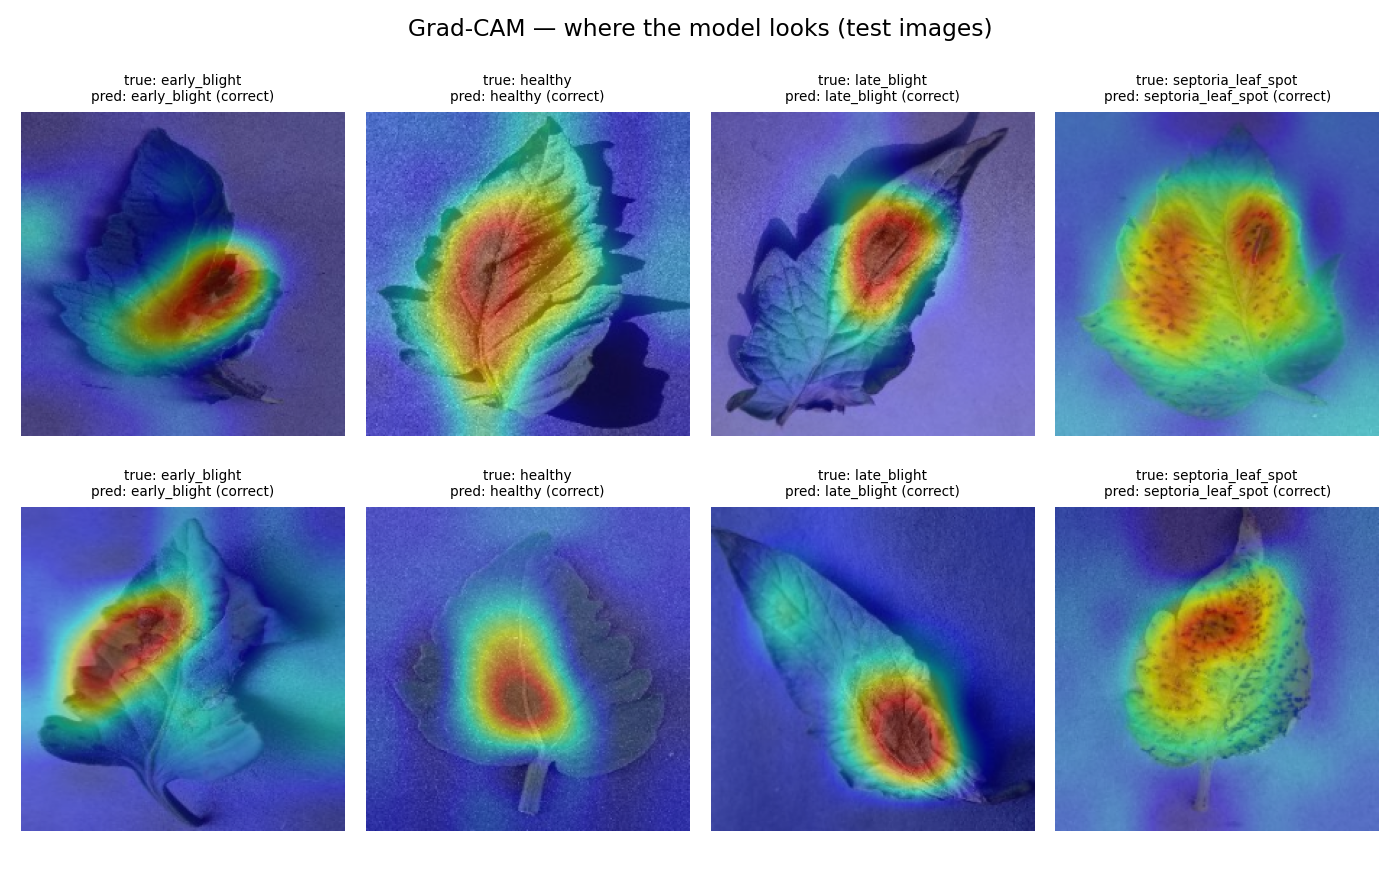

In [10]:
display(Image(str(EVAL / 'gradcam_examples.png')))

## 5. Production model provenance

In [11]:
prod = MODEL_DIR / 'best.keras'
sha = hashlib.sha256(prod.read_bytes()).hexdigest()
print('best.keras SHA256        :', sha)
print('promotion record (new)   :', promotion['new_model_sha256'])
print('evaluated model SHA256   :', metrics['evaluated_model_sha256'])
print('previous model (backup)  :', promotion.get('previous_model_sha256'),
      '->', promotion.get('previous_model_backup'))
assert sha == promotion['new_model_sha256'] == metrics['evaluated_model_sha256']
print('The production model is exactly the model that was evaluated.')

best.keras SHA256        : 499ceca37640900d7d2771dbac1c5f55cf30796875a56b6f4ec584918d92614e
promotion record (new)   : 499ceca37640900d7d2771dbac1c5f55cf30796875a56b6f4ec584918d92614e
evaluated model SHA256   : 499ceca37640900d7d2771dbac1c5f55cf30796875a56b6f4ec584918d92614e
previous model (backup)  : 4022beccda7eb18dc6759f8e5ef8d2825dd3ed43f0615721b069e997063c3f2c -> models/classification/best.keras.bak-20260916-061314
The production model is exactly the model that was evaluated.
